# 05 · Predicting the overnight gap

Notebook 02 found the most consistent pattern so far: the last half hour of the day tends to partly **reverse
overnight**, in every year. Here we try to predict ICHR's overnight gap directly.

- **Decision moment:** today's close (16:00 New York).
- **Target:** `gap = log(tomorrow's open / today's close)`. Only the jump itself, which is what you can trade:
  buy or short at the close, exit at the open.
- **One sample per night:** ~700 nights in total, so this is a *small-data* problem.
- **Inputs per day** (all known at the close):
  - per ticker: this morning's gap, the open→close return, the last-bar return (10 tickers × 3)
  - ICHR's volume today and in the last bar, vs its normal level
  - **earnings tonight** flags for ICHR and 7 related companies (published weeks in advance)
  - `night_days`: calendar days until the next open (1 = weeknight, 3 = weekend)

Code: `src/semiconductor_affairs/overnight.py`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from semiconductor_affairs.baselines import DirectionClassifier, Mean, Zero, linear_on, ridge
from semiconductor_affairs.evaluate import (
    backtest, backtest_summary, metrics, walk_forward, walk_forward_splits,
)
from semiconductor_affairs.features import Dataset
from semiconductor_affairs.lstm import LSTMRegressor
from semiconductor_affairs.overnight import build_daily_panel, make_overnight_dataset

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

panel, next_gap = build_daily_panel()
print(f"{panel.shape[0]} trading days, {panel.shape[1]} features per day")
panel.columns.tolist()

729 trading days, 41 features per day


['ICHR_gap',
 'ICHR_intraday',
 'ICHR_last',
 'LRCX_gap',
 'LRCX_intraday',
 'LRCX_last',
 'AMAT_gap',
 'AMAT_intraday',
 'AMAT_last',
 'KLAC_gap',
 'KLAC_intraday',
 'KLAC_last',
 'ASML_gap',
 'ASML_intraday',
 'ASML_last',
 'TSM_gap',
 'TSM_intraday',
 'TSM_last',
 'NVDA_gap',
 'NVDA_intraday',
 'NVDA_last',
 'UCTT_gap',
 'UCTT_intraday',
 'UCTT_last',
 'SOXX_gap',
 'SOXX_intraday',
 'SOXX_last',
 'QQQ_gap',
 'QQQ_intraday',
 'QQQ_last',
 'ICHR_volume',
 'ICHR_last_volume',
 'earn_ICHR',
 'earn_LRCX',
 'earn_AMAT',
 'earn_KLAC',
 'earn_ASML',
 'earn_TSM',
 'earn_NVDA',
 'earn_UCTT',
 'night_days']

## 1. What does the target look like?

In [2]:
earn_night = panel["earn_ICHR"] == 1
gap = next_gap.dropna() * 100
summary = pd.DataFrame({
    "nights": [len(gap), (~earn_night).sum(), earn_night.sum()],
    "mean %": [gap.mean(), gap[~earn_night].mean(), gap[earn_night].mean()],
    "std %": [gap.std(), gap[~earn_night].std(), gap[earn_night].std()],
    "share up %": [(gap > 0).mean() * 100, (gap[~earn_night] > 0).mean() * 100,
                   (gap[earn_night] > 0).mean() * 100],
}, index=["all nights", "normal nights", "ICHR earnings nights"])
summary.round(2)

,nights,mean %,std %,share up %
all nights,728,0.11,3.55,54.12
normal nights,717,0.20,2.70,54.19
ICHR earnings nights,12,-5.12,18.23,50.00


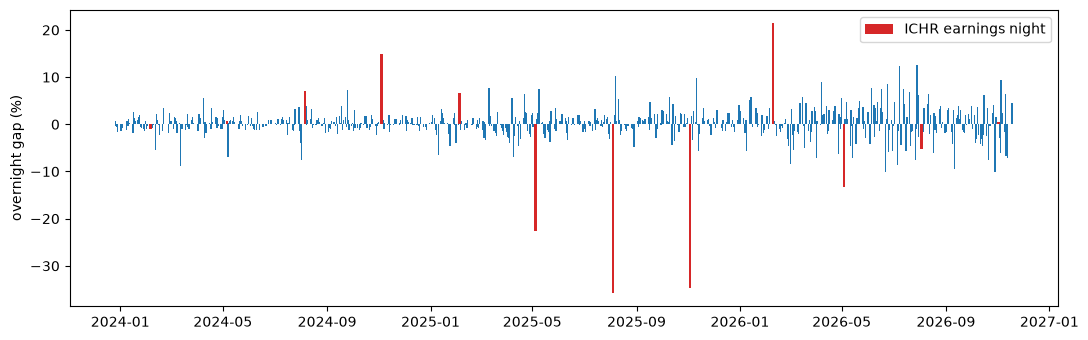

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(gap.index, gap, width=1.5, color="tab:blue")
ax.bar(gap.index[earn_night.reindex(gap.index)], gap[earn_night.reindex(gap.index)],
       width=3, color="tab:red", label="ICHR earnings night")
ax.set_ylabel("overnight gap (%)")
ax.legend()
plt.tight_layout()

**Three things to notice:**
- **Earnings nights are a different world:** ~12 nights with moves of ±18% (two of −35%), against ±2.7% on normal nights.
  Because errors are squared, those 12 nights produce **~40% of all squared movement**. Any MSE-based score is dominated by them.
- **Overnight drift:** the gap is positive on average (+0.11%) and up 54% of the time. This is a known effect: stocks
  earn a large share of their returns overnight. So **"always long"** is a serious baseline, not a strawman.
- The flags say a **big** move is coming, not which **direction**. With 12 ICHR earnings nights, no model can learn
  whether results will disappoint.

In [4]:
# What happens to ICHR on nights when *other* companies report?
earn_cols = [c for c in panel.columns if c.startswith("earn_")]
pd.DataFrame({
    c.removeprefix("earn_"): {
        "nights": int(panel[c].sum()),
        "ICHR gap mean %": gap[panel[c].reindex(gap.index) == 1].mean(),
        "ICHR gap std %": gap[panel[c].reindex(gap.index) == 1].std(),
    } for c in earn_cols
}).T.round(2)

,nights,ICHR gap mean %,ICHR gap std %
ICHR,12.0,-5.12,18.23
LRCX,12.0,0.76,4.67
AMAT,12.0,-1.85,2.26
KLAC,12.0,-0.40,1.49
ASML,11.0,0.33,3.50
TSM,12.0,0.37,3.05
NVDA,12.0,1.55,1.61
UCTT,12.0,0.71,2.64


Customers' earnings (LRCX, ASML, TSM) also make ICHR's night more volatile than a normal night (2.7%).
The means look interesting (e.g. AMAT), but with ~12 nights each, a mean is uncertain by about ±1%.

### The input features in detail
All features are per trading day D and known at D's close. Returns are log returns: 0.01 ≈ +1%.

**Per ticker** (10 tickers, named like `ICHR_gap`, `NVDA_last`):

| Feature | What it measures | Formula |
|---|---|---|
| `gap` | This morning's jump: today's open vs yesterday's close | log(open_D / close_D−1) |
| `intraday` | The move during today's session | log(close_D / open_D) |
| `last` | The last half hour (15:30–16:00), the move into the close | log(close_D / close of the 15:00 bar) |

`gap` + `intraday` = the full close-to-close return. `last` is the part of `intraday` closest to the decision moment;
it's what the reversal model uses (a spike into the close is often partly given back overnight).

**ICHR only:**

| Feature | What it measures |
|---|---|
| `volume` | Today's volume vs a normal day: log(volume_D / median of the previous 20 days). 0 = normal, +0.69 = double, −0.69 = half |
| `last_volume` | The same, for the last half hour only. A spike there often means large end-of-day orders (index funds, someone exiting) |

The median uses the *previous* 20 days, so today's volume doesn't count towards its own "normal".

**Earnings flags** (`earn_ICHR`, `earn_LRCX`, …, 8 in total): 1 if that company publishes results between today's last
bar (15:30) and tomorrow's open (09:30), else 0. This catches US reports after the close (~16:05) and ASML/TSMC reports
before the US open. Known in advance; it signals a *big* move, not its direction.

**`night_days`:** calendar days until the next open: 1 on a weeknight, 3 over a weekend, 4 over a long weekend.

10 × 3 + 2 + 8 + 1 = **41 features per day**; the LSTM sees the last 10 days of them.

## 2. Models
| Model | Idea |
|---|---|
| zero | gap is unpredictable |
| mean (always long) | average training gap, i.e. bet on the overnight drift |
| reversal | linear regression on just ICHR's and SOXX's last-bar returns (the notebook 02 finding) |
| ridge | all 41 features of today |
| direction classifier | logistic regression: up or down, ignores size |
| LSTM | sequence of the **last 10 days** (one step per day), hidden 8 |

Same quarterly walk-forward as before (test from 2025-01). Every model sees the same nights.

In [5]:
LSTM_DAYS = 10
raw = {1: make_overnight_dataset(days=1), LSTM_DAYS: make_overnight_dataset(days=LSTM_DAYS)}
common = raw[LSTM_DAYS].timestamps

def restrict(d: Dataset) -> Dataset:
    keep = np.isin(d.timestamps, common)
    return Dataset(d.X[keep], d.y[keep], d.timestamps[keep], d.feature_names)

data = {k: restrict(v) for k, v in raw.items()}
today = data[1]
names = today.feature_names
splits = walk_forward_splits(common)
print("train / test nights per fold:", [(len(a), len(b)) for a, b in splits])

reversal_cols = [names.index("ICHR_last"), names.index("SOXX_last")]
preds = {
    "zero": walk_forward(Zero, today, splits),
    "mean (always long)": walk_forward(Mean, today, splits),
    "reversal": walk_forward(lambda: linear_on(reversal_cols), today, splits),
    "ridge": walk_forward(ridge, today, splits),
    "direction classifier": walk_forward(DirectionClassifier, today, splits),
}

train / test nights per fold: [(226, 60), (286, 62), (348, 64), (412, 64), (476, 61), (537, 62), (599, 64), (663, 35)]


### LSTM: why 20 seeds?
With only ~230–660 training nights, a single LSTM's result depends heavily on its random starting weights.
We train 20 and **average their predictions** (an ensemble). We also keep each single run, to see the spread.
(About 2 minutes.)

In [6]:
def make_lstm(seed):
    return lambda: LSTMRegressor(hidden=8, batch_size=32, patience=10, max_epochs=200, seed=seed)

lstm_runs = [walk_forward(make_lstm(s), data[LSTM_DAYS], splits) for s in range(20)]
preds["LSTM (20-seed avg)"] = sum(lstm_runs) / len(lstm_runs)

## 3. Error metrics: all nights vs normal nights
Skill vs zero, computed twice: on all test nights, and without ICHR's earnings nights.
The direction classifier only predicts direction, so its error metrics are meaningless and left out.

In [7]:
y = today.y
earn = today.X[:, -1, names.index("earn_ICHR")] == 1
idx = preds["zero"].index
print(f"test nights: {len(idx)}, of which ICHR earnings nights: {earn[idx].sum()}")

rows = {}
for name, p in preds.items():
    yy, pp, e = y[p.index], p.to_numpy(), earn[p.index]
    m_all, m_norm = metrics(yy, pp), metrics(yy[~e], pp[~e])
    rows[name] = {
        "skill all %": m_all["skill vs zero %"],
        "skill normal nights %": m_norm["skill vs zero %"],
        "direction acc %": m_norm["direction acc %"],
        "corr (normal)": m_norm["corr"],
        "pred std %": pp.std() * 100,
    }
table = pd.DataFrame(rows).T
table.loc["direction classifier", ["skill all %", "skill normal nights %", "corr (normal)", "pred std %"]] = np.nan
table.round(2)

test nights: 472, of which ICHR earnings nights: 8


,skill all %,skill normal nights %,direction acc %,corr (normal),pred std %
zero,0.00,0.00,NaN,NaN,0.00
mean (always long),-0.15,0.15,55.26,-0.06,0.06
reversal,0.90,1.48,51.54,0.11,0.41
ridge,-4.77,0.59,53.51,0.05,0.39
direction classifier,NaN,NaN,54.61,NaN,NaN
LSTM (20-seed avg),-0.08,1.12,54.82,0.08,0.33


## 4. Backtest: would it make money?
Each night, one trade that only holds the **overnight** move:
1. **At the close (16:00):** prediction positive → **buy** 1 unit. Negative → **short** 1 unit (borrow shares and sell
   them, hoping to buy them back cheaper).
2. **At the open (09:30) – "exit at the open":** undo it: sell what you bought, or buy back and return the borrowed shares.
3. **Result:** long earns the gap log(open / close); short earns minus the gap.

You're out of the market during the day and decide again at the next close. That's also why the cost is counted
twice per night: once to get in, once to get out.
**Costs** are per side, in basis points (1 bp = 0.01%). Using the closing and opening *auctions* (market-on-close /
market-on-open orders) avoids the bid-ask spread, so ~2–5 bp is realistic. 10 bp is a pessimistic case.
"Skip earnings" = don't trade on ICHR earnings nights (a pure gamble).

**How to read the table:**

| Column | Meaning |
|---|---|
| `trades` | Nights with a position (long or short). Lower than 472 because earnings nights are skipped |
| `long %` | Share of **all** test nights spent long (skipped nights count as not long) |
| `total %` | Sum of all nightly results after costs, ~470 nights (~1.9 years). Not compounded: like betting the same fixed amount every night |
| `per trade %` | Average result per traded night. 5 bp/side costs 0.10% of this per trade |
| `win rate %` | Share of traded nights that made money. Above 50% isn't enough if the losses are bigger than the wins |
| `sharpe` | Return per unit of risk, per year: mean nightly result ÷ its std × √252. < 0.5 weak, ~1 good, > 2 suspiciously good |

`long %` and `sharpe` use all nights (skipped = 0); `per trade %` and `win rate %` only the traded ones.

**What the costs do and don't cover.** The bp per side covers the fee and the price you get when trading. *Not* included:
- **Auction vs Yahoo price:** we use the close of Yahoo's last hourly bar and the open of its first. The official
  closing/opening auction prices, where you'd actually trade, can differ a little.
- **Short-borrow fee:** interest for each night you borrow shares to short. Usually small for ICHR, but not zero.
- **Price impact:** a large order pushes the price against you. Irrelevant at small size.

**Long or flat:** the same signal without shorting. Positive prediction: buy at the close, sell at the open; negative: stay in cash. No borrow fees and no unlimited loss, but no profit on the nights the model expects a drop. Column `long or flat total %`.

In [ ]:
bt_rows = {}
for name, p in preds.items():
    if name == "zero":
        continue
    for cost in [0, 2, 5, 10]:
        args = (y[p.index], p.to_numpy(), cost)
        bt = backtest(*args, skip=earn[p.index])
        flat = backtest(*args, skip=earn[p.index], long_only=True)
        bt_rows[(name, cost)] = {
            **backtest_summary(bt),
            "long or flat total %": flat["pnl"].sum() * 100,
        }
bt_table = pd.DataFrame(bt_rows).T
bt_table.index.names = ["model", "cost bp/side"]
bt_table.round(2)


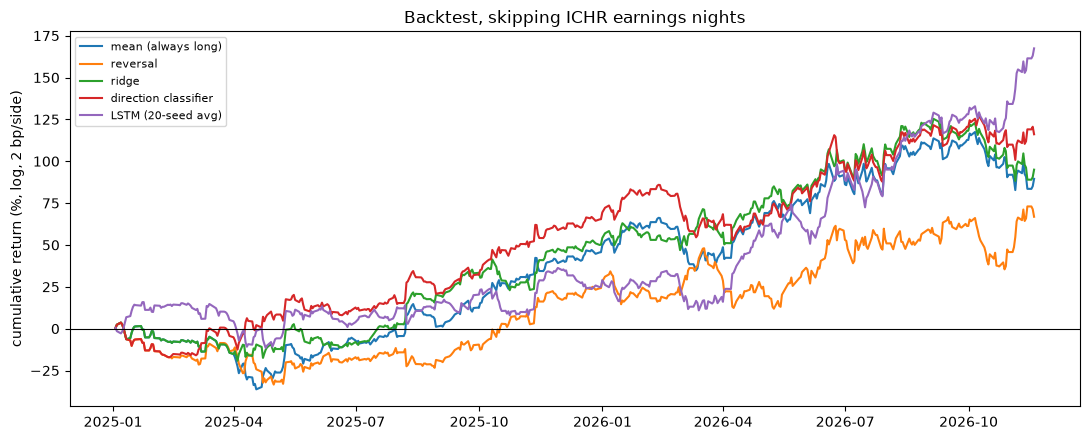

In [9]:
ts = today.timestamps
fig, ax = plt.subplots(figsize=(11, 4.5))
for name, p in preds.items():
    if name == "zero":
        continue
    bt = backtest(y[p.index], p.to_numpy(), cost_bps=2, skip=earn[p.index])
    ax.plot(ts[p.index], bt["pnl"].cumsum().to_numpy() * 100, label=name)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative return (%, log, 2 bp/side)")
ax.set_title("Backtest, skipping ICHR earnings nights")
ax.legend(fontsize=8)
plt.tight_layout()

### LSTM: long/short vs long or flat
How much does the LSTM give up by never shorting? Same 20-seed average, skipping earnings nights.

**Why not short?** Shorting means borrowing shares: you pay interest, the broker can recall them, you need a margin
account, and the possible loss has no limit (a takeover announcement can mean +50% overnight).

**Why not hold a base position instead** (e.g. own 10 units, buy 1 more on "up" nights, sell 1 on "down" nights)?
Your result is then *10 units of buy-and-hold ICHR* + *the ±1 signal strategy*. You never short, but you carry ten
times the strategy's size in ICHR risk all day and every night, including earnings nights: one −35% night costs 3.5
units, more than the strategy earns in a year. Long or flat avoids both problems.

In [ ]:
p = preds["LSTM (20-seed avg)"]
p_long = preds["mean (always long)"]
variants = {
    "LSTM long/short": (p, False),
    "LSTM long or flat": (p, True),
    "always long": (p_long, False),
}
rows, curves = {}, {}
for name, (pp, long_only) in variants.items():
    for cost in [0, 2, 5]:
        bt = backtest(y[pp.index], pp.to_numpy(), cost, skip=earn[pp.index], long_only=long_only)
        bt.index = ts[pp.index]
        by_year = bt["pnl"].groupby(bt.index.year).sum() * 100
        rows[(name, cost)] = {
            **backtest_summary(bt),
            **{f"{yr} %": v for yr, v in by_year.items()},
        }
        if cost == 2:
            curves[name] = bt["pnl"].cumsum() * 100

fig, ax = plt.subplots(figsize=(11, 4))
for name, c in curves.items():
    ax.plot(c.index, c.to_numpy(), label=name, **({"color": "k", "ls": "--"} if name == "always long" else {}))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative return (%, log, 2 bp/side)")
ax.set_title("LSTM: long/short vs long or flat")
ax.legend(fontsize=8)
plt.tight_layout()

lf_table = pd.DataFrame(rows).T
lf_table.index.names = ["strategy", "cost bp/side"]
lf_table.round(2)


## 5. Is it luck?
Three checks for the best-looking result:
1. **Random strategies:** go long or short at random, with the same share of long nights as the LSTM, 5,000 times.
   Where does the LSTM land in that distribution?
2. **Single seeds:** what did each of the 20 individual LSTMs earn?
3. **Concentration:** what's left after removing the 10 best nights? Per year?

**One thing these checks can't fix: we tried 6 models and look at the best one.** Even if all six had no skill, their
backtests would come out higher or lower by luck. Picking the best partly picks the *luckiest*, so its score is real
skill + the best luck out of 6 draws. The same problem as the many cells in notebook 02's heatmap (the shuffle test).
The 99.3% "beats random" ignores that we chose the LSTM from 6 candidates: with 6 tries, landing in the top 1% by luck
alone is about 6× as likely.

In the histogram, the top panel shows the random strategies, the bottom panel one dot per single LSTM seed
(same x-axis), with always long as a dashed line.

LSTM avg: 186%   beats 99.3% of random strategies
single seeds: min -26%, median 74%, max 157%


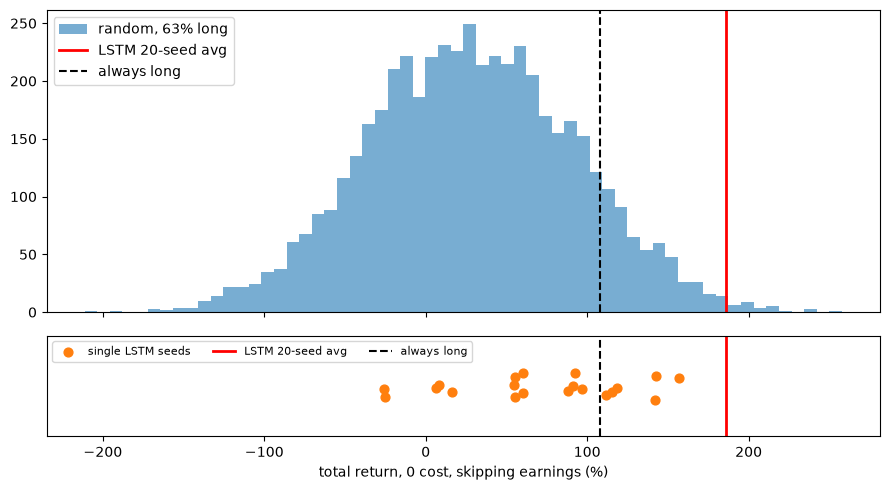

In [10]:
p_lstm = preds["LSTM (20-seed avg)"]
yy, ee = y[idx], earn[idx]
long_share = (p_lstm.to_numpy() > 0).mean()
rng = np.random.default_rng(0)
random_totals = np.array([
    backtest(yy, np.where(rng.random(len(yy)) < long_share, 1, -1), 0, skip=ee)["pnl"].sum() * 100
    for _ in range(5000)
])
lstm_total = backtest(yy, p_lstm.to_numpy(), 0, skip=ee)["pnl"].sum() * 100
single = [backtest(y[r.index], r.to_numpy(), 0, skip=earn[r.index])["pnl"].sum() * 100 for r in lstm_runs]

p_long = preds["mean (always long)"]
long_total = backtest(y[p_long.index], p_long.to_numpy(), 0, skip=earn[p_long.index])["pnl"].sum() * 100

# top: 5,000 random strategies; bottom: one dot per single LSTM seed (same x-axis)
fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(9, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
ax.hist(random_totals, bins=60, alpha=0.6, label=f"random, {long_share:.0%} long")
ax2.scatter(single, np.random.default_rng(1).uniform(-0.3, 0.3, len(single)),
            color="tab:orange", s=40, label="single LSTM seeds")
ax2.set_ylim(-1, 1)
ax2.set_yticks([])
for a in (ax, ax2):
    a.axvline(lstm_total, color="r", lw=2, label="LSTM 20-seed avg")
    a.axvline(long_total, color="k", ls="--", lw=1.5, label="always long")
ax.legend(loc="upper left")
ax2.legend(loc="upper left", fontsize=8, ncols=3)
ax2.set_xlabel("total return, 0 cost, skipping earnings (%)")
plt.tight_layout()
print(f"LSTM avg: {lstm_total:.0f}%   beats {np.mean(random_totals < lstm_total):.1%} of random strategies")
print(f"single seeds: min {min(single):.0f}%, median {np.median(single):.0f}%, max {max(single):.0f}%")

Each single LSTM over time, next to their average and always long (2 bp/side, skipping earnings nights).
The average is smoother and higher than most single runs: averaging cancels each run's random mistakes.

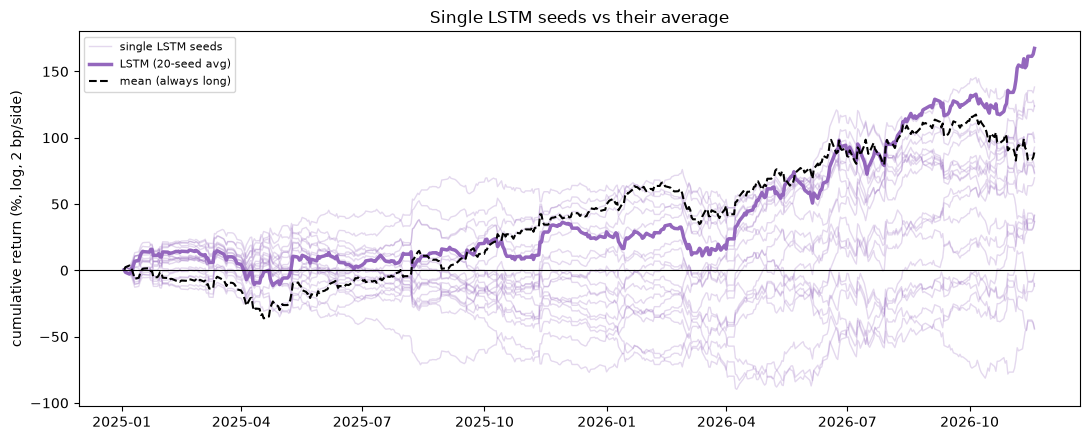

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, r in enumerate(lstm_runs):
    bt = backtest(y[r.index], r.to_numpy(), cost_bps=2, skip=earn[r.index])
    ax.plot(ts[r.index], bt["pnl"].cumsum().to_numpy() * 100,
            color="tab:purple", alpha=0.25, lw=1, label="single LSTM seeds" if i == 0 else None)
for name, style in [("LSTM (20-seed avg)", dict(color="tab:purple", lw=2.5)),
                    ("mean (always long)", dict(color="k", ls="--", lw=1.5))]:
    p = preds[name]
    bt = backtest(y[p.index], p.to_numpy(), cost_bps=2, skip=earn[p.index])
    ax.plot(ts[p.index], bt["pnl"].cumsum().to_numpy() * 100, label=name, **style)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative return (%, log, 2 bp/side)")
ax.set_title("Single LSTM seeds vs their average")
ax.legend(fontsize=8)
plt.tight_layout()


In [12]:
rows = {}
for name, p in preds.items():
    if name == "zero":
        continue
    bt = backtest(y[p.index], p.to_numpy(), 0, skip=earn[p.index])
    bt.index = ts[p.index]
    by_year = bt["pnl"].groupby(bt.index.year).sum() * 100
    rows[name] = {
        **{f"{yr} %": v for yr, v in by_year.items()},
        "without best 10 nights %": bt["pnl"].sort_values().iloc[:-10].sum() * 100,
    }
pd.DataFrame(rows).T.round(1)

,2025 %,2026 %,without best 10 nights %
mean (always long),59.6,48.5,13.1
reversal,38.1,47.3,-12.2
ridge,64.0,49.5,17.7
direction classifier,79.3,55.4,39.8
LSTM (20-seed avg),38.9,147.1,88.6


## Conclusions (2026-11-20)

1. **For the first time, models beat zero, but only on normal nights.** Skill without ICHR earnings nights: reversal +1.5%,
   LSTM +1.1%, ridge +0.6% (the hourly models in notebooks 03–04 were all ≤ 0). With earnings nights included, ridge drops to
   −4.8%: a handful of ±20–35% nights wipe out everything else.
2. **The earnings flag is useful as a *risk filter*, not a predictor.** It tells you a big move is coming, not which way.
   The sensible use is "don't trade tonight", which is what the backtest's skip does.
3. **"Always long" is the bar to beat.** The overnight drift alone made +108% over the test period (+62% at 5 bp/side).
   Ridge and the reversal model don't clearly beat it; the direction classifier does a bit (+135%).
4. **The 20-seed LSTM looks best by far:** +186% gross, +140% at 5 bp/side, Sharpe ~1.5–2, beating 99.3% of random
   strategies with the same long share, and keeping most of it without its 10 best nights. **But:**
   - **It's almost all 2026** (+147%). In 2025 it made +39%, *less* than always long (+60%).
   - **Single LSTMs are a lottery:** −26% to +157%, median +74%, which is below always long. The result only appears after
     averaging 20 of them.
   - **We tried 6 models and are looking at the best one,** so part of its lead is luck (section 5).
   - **The backtest is idealised:** trading costs are included, but it still assumes Yahoo's prices equal the
     auction prices, and ignores short-borrow fees and price impact (section 4).
5. **Long or flat (never short) keeps most of it:** LSTM +147% gross, +118% at 5 bp/side (long/short: +186% / +140%),
   with the same Sharpe (~1.6 at 5 bp) and only 290 instead of 464 trades. The short nights lost money until autumn
   2026 and only paid off in the last ~6 weeks. Long or flat is the safer live variant: no borrow fees, no unlimited
   loss. In 2025 it still only matches always long at 5 bp/side (+35% each).

**Verdict: promising, not proven.** The overnight gap is clearly more predictable than the next hour. Whether the LSTM's edge
is real can only be shown on nights it has never seen. That's the natural link to deployment: run the model live every
evening and record predicted vs actual gaps (paper trading). That's a true out-of-sample test that no backtest can replace.